# Nhận diện bản thu âm nhạc từ đoạn âm thanh ngắn
Khi chỉ có 5 giây âm thanh, máy có thể tìm đúng bản thu trong kho không?
Nếu trộn thêm tiếng xì, cách nhận diện nào giữ được nhiều câu trả lời đúng nhất?

Thí nghiệm này so sánh bốn cách nhận diện trên năm bản thu thật. Trong lần
chạy đã lưu, phương pháp dấu vân tay nhận diện đúng **23/25** đoạn ở mức nhiễu
mạnh nhất. Kết quả này đo khả năng truy tìm trong một kho đã biết.

**Luồng xử lý** — Đoạn âm thanh → Phổ theo thời gian → Đặc trưng hoặc dấu vân tay
→ Điểm đối sánh → Tên bản thu → Đánh giá.

Mỗi ô mã có phần **Hiểu nhanh** để giải thích ý tưởng bằng ví dụ quen thuộc và
phần **Trong ô mã** để đối chiếu cách triển khai.

## Thiết lập thí nghiệm

Mở notebook bằng môi trường Python của dự án và chọn **Run All**. Có thể nghe
và xem các đầu ra đã lưu ngay khi mở. Lần chạy đầu ở môi trường mới cần Internet
để tải bản thu. Nếu Colab báo thiếu thư viện, chạy
`%pip install pooch soundfile` trong một ô riêng rồi chọn **Run All**.

**Hiểu nhanh.** Trước khi chơi một ván, cả lớp thống nhất luật. Ở đây mọi cách
đoán đều nghe cùng một đoạn dài 5 giây.

**Trong ô mã.** Nạp thư viện, đặt tần số lấy mẫu chung 12.000 mẫu/giây, cửa sổ
phân tích 1.024 mẫu, bước dịch 240 mẫu và seed 501 để lặp lại phép lấy mẫu.

In [1]:
from collections import Counter, defaultdict
from fractions import Fraction
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import soundfile as sf
from IPython.display import Audio, Markdown, display
from scipy.fft import dct
from scipy.ndimage import maximum_filter
from scipy.signal import resample_poly, stft
from scipy.spatial.distance import cdist

plt.rcParams.update({"figure.dpi": 115, "font.size": 11, "axes.spines.top": False})
SR = 12_000
FRAME, HOP = 1024, 240
CLIP_SECONDS, REFERENCE_SECONDS = 5, 45
SEED = 501

## 1. Mô phỏng cao độ bằng hai sóng sin

**Hiểu nhanh.** Dây đàn rung chậm cho âm trầm. Rung nhanh cho âm cao. Bấm nghe
hai âm nối tiếp rồi đếm các đỉnh trong cùng một khoảng thời gian. Âm thứ hai
có khoảng cách giữa các đỉnh bằng một nửa âm thứ nhất.

**Trong ô mã.** Tạo hai tín hiệu sin 220 Hz và 440 Hz có cùng biên độ để chỉ
thay đổi tần số. Phát mỗi âm một giây và phóng to 22 mili giây đầu của mỗi sóng.
Một hertz là một lần lặp trong một giây.

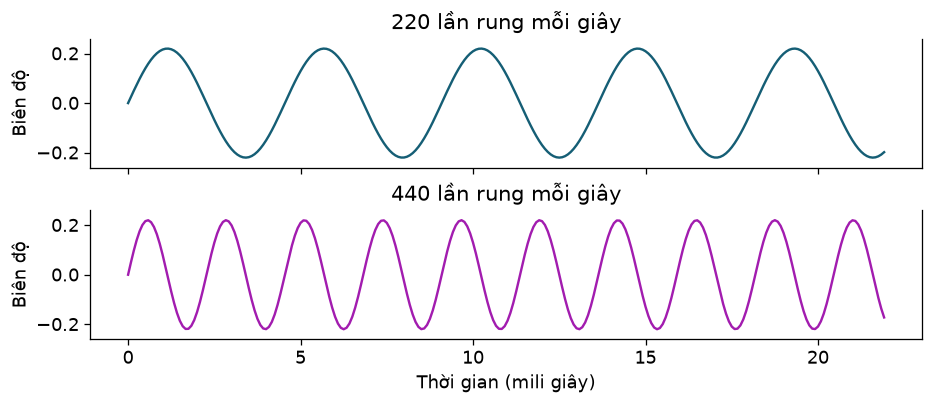

In [2]:
tone_times = np.arange(SR) / SR
tones = [0.22 * np.sin(2 * np.pi * hz * tone_times) for hz in (220, 440)]
display(Audio(np.concatenate([tones[0], np.zeros(SR // 4), tones[1]]),
              rate=SR, normalize=False))

fig, axes = plt.subplots(2, 1, figsize=(8, 3.4), sharex=True, layout="constrained")
for ax, wave, hz, color in zip(axes, tones, (220, 440), ("#155e75", "#a21caf")):
    shown = tone_times < 0.022
    ax.plot(tone_times[shown] * 1000, wave[shown], color=color)
    ax.set(title=f"{hz} lần rung mỗi giây", ylabel="Biên độ", ylim=(-0.26, 0.26))
axes[-1].set_xlabel("Thời gian (mili giây)")
plt.show()

## 2. Dữ liệu và tiền xử lý

| Mã | Tác phẩm | Bản thu |
| --- | --- | --- |
| A | Für Elise | Piano, V. Gao. [Wikimedia Commons, CC0](https://commons.wikimedia.org/wiki/File:FurElise.ogg) |
| B | Jingle Bells | Bản phối của Kevin MacLeod (incompetech.com). [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Jingle_Bells.ogg) · [CC BY 3.0](https://creativecommons.org/licenses/by/3.0/) |
| C | Maple Leaf Rag | United States Marine Band, 1906. [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:1906_-_Scott_Joplin%27s_Maple_Leaf_Rag_(1899)_played_by_the_United_States_Marine_Band.ogg) |
| D | In the Hall of the Mountain King | Czech National Symphony Orchestra, dự án Musopen. [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Musopen_-_In_the_Hall_Of_The_Mountain_King.ogg) |
| E | Giao hưởng số 5, chương I | Skidmore College Orchestra, qua Musopen. [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Ludwig_van_Beethoven_-_symphony_no._5_in_c_minor,_op._67_-_i._allegro_con_brio.ogg) |

**Hiểu nhanh.** Giống như xếp năm bản thu vào năm ngăn có nhãn. Bấm nghe
bảy giây đầu để làm quen trước khi thử đoán một đoạn bất kỳ.

**Trong ô mã.** Tải hoặc đọc lại các tệp đã lưu, kiểm tra SHA-256, lấy 45 giây
đầu của mỗi bản, trộn các kênh thành mono, đổi về 12 kHz và chuẩn hóa đỉnh
theo từng bản. Các đoạn có nhiễu được tạo sau bước này.

In [3]:
BASE_URL = "https://upload.wikimedia.org/wikipedia/commons/"
RECORDINGS = {
    "A": ("Für Elise", "fur-elise.ogg", "7/7b/FurElise.ogg"),
    "B": ("Jingle Bells", "jingle-bells.ogg",
          "f/f0/Jingle_Bells_%2890bpm%29_%28Kevin_MacLeod%29_%28ISRC_USUAN1100187%29.oga"),
    "C": ("Maple Leaf Rag", "maple-leaf-rag.ogg",
          "3/3a/1906_-_Scott_Joplin%27s_Maple_Leaf_Rag_%281899%29_played_by_the_United_States_Marine_Band.ogg"),
    "D": ("In the Hall of the Mountain King", "mountain-king.ogg",
          "b/bb/Musopen_-_In_the_Hall_Of_The_Mountain_King.ogg"),
    "E": ("Giao hưởng số 5", "symphony-5.ogg",
          "e/e6/Ludwig_van_Beethoven_-_symphony_no._5_in_c_minor%2C_op._67_-_i._allegro_con_brio.ogg"),
}
FILE_HASHES = {
    "fur-elise.ogg": "8deefb57df989a2b53a6bdd3e59813b6c34d61dca666caa39e53fa9597b378e3",
    "jingle-bells.ogg": "67216c89aa23862960d51d4593c6f3a7a00b34f6a0f525589299ebb3f2847080",
    "maple-leaf-rag.ogg": "90ed6bbb9554a5d6ffc63f599704dc185209e4155eaef1d501554a468ee32095",
    "mountain-king.ogg": "3bfa7424d3a148f1482a44688b77eb9138a7cea6cff7474799f1329181ab3342",
    "symphony-5.ogg": "663cfa62707be850a51ec8cd7b51b95595a9ee010f3eefea16e1dd46d54a9d95",
}

project = next((p for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "notebooks").is_dir()
                and ((p / "pyproject.toml").is_file()
                     or (p / "data/raw/audio-fingerprints").is_dir())), None)
cache_dir = project / "data/raw/audio-fingerprints" if project else Path("audio-fingerprints")
downloader = pooch.HTTPDownloader(headers={"User-Agent": "DSP501 classroom notebook"},
                                  timeout=60)

def load_reference(filename, remote_path):
    path = pooch.retrieve(BASE_URL + remote_path, known_hash=FILE_HASHES[filename],
                          fname=filename, path=cache_dir, downloader=downloader)
    with sf.SoundFile(path) as recording:
        rate = recording.samplerate
        samples = recording.read(REFERENCE_SECONDS * rate, dtype="float32", always_2d=True)
    ratio = Fraction(SR, rate)
    mono = resample_poly(samples.mean(axis=1), ratio.numerator, ratio.denominator)
    if len(mono) != REFERENCE_SECONDS * SR:
        raise ValueError(f"Bản thu quá ngắn: {filename}")
    return mono / np.max(np.abs(mono))

references = {key: load_reference(filename, remote)
              for key, (_, filename, remote) in RECORDINGS.items()}

for key, (title, _, _) in RECORDINGS.items():
    display(Markdown(f"**{key} · {title}**"))
    display(Audio(references[key][:7 * SR], rate=SR))

**A · Für Elise**

**B · Jingle Bells**

**C · Maple Leaf Rag**

**D · In the Hall of the Mountain King**

**E · Giao hưởng số 5**

## 3. Từ dạng sóng đến phổ theo thời gian

**Hiểu nhanh.** Hình sóng cho thấy âm thanh dao động mạnh hay nhẹ theo thời gian.
Bức tranh bên dưới cho thấy lúc nào có âm trầm, lúc nào có âm cao. Nhìn sang phải
là đi tới đoạn nhạc tiếp theo. Nhìn lên là tới tần số cao hơn. Vòng xanh khoanh
những điểm sáng nổi bật mà máy sẽ giữ để so sánh.

**Trong ô mã.** STFT chia âm thanh thành khung chồng lấn, rồi tính phổ của từng
khung bằng cửa sổ Hann. Với 12 kHz, mỗi khung dài khoảng 85,3 ms và dịch 20 ms
mỗi lần. Màu thể hiện độ lớn phổ theo dB tương đối với đỉnh mạnh nhất của đoạn.
Một điểm được giữ nếu là cực đại trong vùng 11 ô tần số × 13 khung thời gian,
thuộc dải 120–3.500 Hz và lớn hơn 1,8% độ lớn cực đại của phổ.

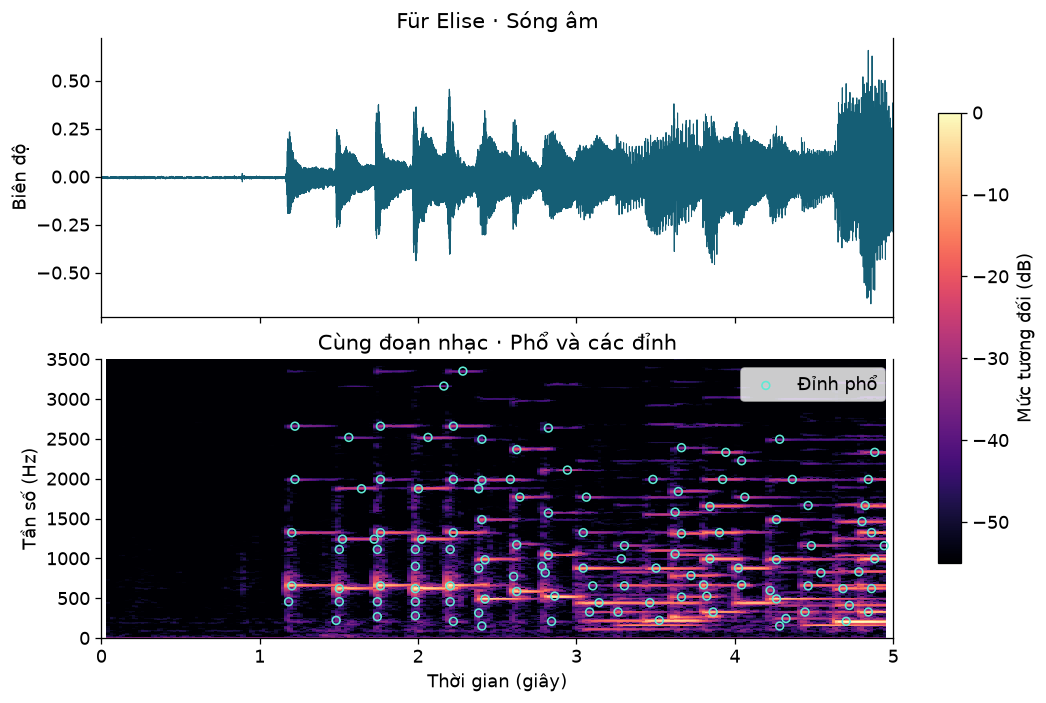

In [4]:
def spectrum(wave):
    return stft(wave, fs=SR, nperseg=FRAME, noverlap=FRAME - HOP,
                boundary=None, padded=False)

def spectral_peaks(frequencies, magnitude):
    nearby = maximum_filter(magnitude, size=(11, 13))
    audible_band = (frequencies >= 120) & (frequencies <= 3500)
    strong = (magnitude == nearby) & (magnitude > 0.018 * magnitude.max())
    frequency_bins, frames = np.nonzero(strong & audible_band[:, None])
    return sorted(zip(frames.tolist(), frequency_bins.tolist()))

example = references["A"][SR:6 * SR]
frequencies, times, complex_spectrum = spectrum(example)
magnitude = np.abs(complex_spectrum)
peaks = spectral_peaks(frequencies, magnitude)

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, layout="constrained")
axes[0].plot(np.arange(len(example)) / SR, example, color="#155e75", linewidth=0.65)
axes[0].set(title="Für Elise · Sóng âm", ylabel="Biên độ")
decibels = 20 * np.log10(np.maximum(magnitude / magnitude.max(), 1e-5))
image = axes[1].pcolormesh(times, frequencies, decibels, shading="auto",
                           cmap="magma", vmin=-55, vmax=0)
peak_times, peak_frequencies = zip(*peaks)
axes[1].scatter(times[list(peak_times)], frequencies[list(peak_frequencies)],
                facecolors="none", edgecolors="#5eead4", s=24, label="Đỉnh phổ")
axes[1].set(title="Cùng đoạn nhạc · Phổ và các đỉnh", xlabel="Thời gian (giây)",
            ylabel="Tần số (Hz)", ylim=(0, 3500), xlim=(0, 5))
axes[1].legend(loc="upper right")
fig.colorbar(image, ax=axes, label="Mức tương đối (dB)", shrink=0.75)
plt.show()

## 4. Trích xuất đặc trưng và đối sánh

### 4.1 Chroma và MFCC

**Hiểu nhanh.** Hãy tạo một tấm thẻ cho mỗi bài. Một mặt ghi những nhóm nốt
nghe rõ nhất. Mặt kia tóm tắt màu âm, như cảm giác khác nhau khi đàn piano và
sáo chơi cùng một nốt. Nếu gộp cả đoạn vào một thẻ, thứ tự các nốt sẽ mất đi.

**Trong ô mã.** Chroma gộp độ lớn phổ vào 12 lớp cao độ theo nốt gần nhất,
bỏ qua quãng tám. MFCC lấy 13 hệ số đầu từ biến đổi cosin rời rạc của log
năng lượng trên 32 bộ lọc Mel. Với Cosine và 3-NN, lấy trung bình theo thời gian
rồi chuẩn hóa từng khối đặc trưng để hai khối có trọng số bằng nhau. Với DTW,
giữ thứ tự của chroma và gộp mỗi bốn khung thành một bước khoảng 80 ms.

In [5]:
def unit_rows(values):
    return values / np.maximum(np.linalg.norm(values, axis=-1, keepdims=True), 1e-12)

def to_mel(hz):
    return 2595 * np.log10(1 + hz / 700)

fft_frequencies = np.fft.rfftfreq(FRAME, 1 / SR)
mel_edges = np.linspace(to_mel(40), to_mel(SR / 2), 34)
mel_frequencies = to_mel(fft_frequencies)[None, :]
low, middle, high = [edge[:, None] for edge in
                     (mel_edges[:-2], mel_edges[1:-1], mel_edges[2:])]
mel_filters = np.maximum(0, np.minimum((mel_frequencies - low) / (middle - low),
                                       (high - mel_frequencies) / (high - middle)))

note_band = (fft_frequencies >= 100) & (fft_frequencies <= 3500)
note_numbers = np.rint(69 + 12 * np.log2(fft_frequencies[note_band] / 440)).astype(int)
chroma_bins = (np.arange(12)[:, None] == note_numbers % 12).astype(float)

def features(magnitude):
    power = magnitude ** 2
    mel_energy = mel_filters @ power
    mfcc = dct(np.log(np.maximum(mel_energy, 1e-10)), axis=0, norm="ortho")[:13].T
    chroma = unit_rows((chroma_bins @ magnitude[note_band]).T)
    return mfcc, chroma

def card(mfcc, chroma):
    return np.r_[unit_rows(mfcc.mean(axis=0)), unit_rows(chroma.mean(axis=0))] / np.sqrt(2)

def sequence(chroma):
    # Gộp mỗi nhóm 4 lát nhằm giảm lượng tính toán của DTW.
    groups = len(chroma) // 4
    return unit_rows(chroma[:4 * groups].reshape(groups, 4, 12).mean(axis=1))

### 4.2 Dấu vân tay và DTW

**Hiểu nhanh.** Với dấu vân tay, nối hai điểm sáng và ghi khoảng cách của chúng
theo thời gian. Khi nhiều cặp cùng chỉ về một vị trí của bản gốc, đó là một
dấu hiệu mạnh. Với DTW, tưởng tượng hai người vỗ theo cùng một nhịp, một người
đôi lúc chậm lại. Ta có thể dãn nhẹ cách ghép các nhịp để chúng khớp nhau.

**Trong ô mã.** Dấu vân tay dùng khóa gồm hai ô tần số đã lượng tử hóa và độ
trễ đã lượng tử hóa. Bộ đối sánh đếm phiếu theo độ lệch mốc của hai bản, cho
phép sai lệch ±1 khung (20 ms). DTW dùng khoảng cách Euclid giữa các vector
chroma, quy hoạch động để khớp chuỗi con và chia chi phí cho số bước đầu vào.

In [6]:
def fingerprints(magnitude):
    peaks = spectral_peaks(fft_frequencies, magnitude)
    for index, (anchor_time, anchor_freq) in enumerate(peaks):
        paired = 0
        for target in range(index + 1, len(peaks)):
            target_time, target_freq = peaks[target]
            delay = target_time - anchor_time
            if delay > 45:
                break
            if delay >= 5:
                token = (anchor_freq // 2, target_freq // 2, round(delay / 2))
                yield token, anchor_time
                paired += 1
                if paired == 8:
                    break

def fingerprint_votes(magnitude):
    offsets = {key: Counter() for key in references}
    for token, query_time in fingerprints(magnitude):
        for key, reference_time in fingerprint_index.get(token, ()):
            offsets[key][reference_time - query_time] += 1
    # Cho phép lệch một lát phổ về mỗi phía (20 ms).
    return {key: max((hits + counts[offset - 1] + counts[offset + 1]
                     for offset, hits in counts.items()), default=0)
            for key, counts in offsets.items()}

def subsequence_dtw(query, reference):
    distances = cdist(query, reference, metric="euclidean")
    previous = np.zeros(len(reference) + 1)
    for row in distances:
        current = np.full(len(reference) + 1, np.inf)
        for column, cost in enumerate(row, start=1):
            current[column] = cost + min(previous[column - 1], previous[column],
                                         current[column - 1])
        previous = current
    return previous[1:].min() / len(query)

### 4.3 Lập chỉ mục và chọn kết quả

**Hiểu nhanh.** Kho chuẩn bị trước các tấm thẻ và dấu vân tay. Khi có đoạn mới,
cosine so với một thẻ cho mỗi bản thu. 3-NN cho ba đoạn có thẻ gần nhất bỏ phiếu.
DTW tìm chuỗi khớp nhất. Dấu vân tay tìm bản thu có cụm phiếu khớp lớn nhất.

**Trong ô mã.** Mỗi bản thu có một vector trung bình cho cosine, các cửa sổ
chồng lấn cho 3-NN, một chuỗi chroma cho DTW và các khóa ghép cặp đỉnh cho tra
cứu dấu vân tay. Cosine được tính bằng tích vô hướng sau chuẩn hóa. Khi 3-NN
hòa phiếu, láng giềng gần nhất trong nhóm hòa quyết định.

In [7]:
fingerprint_index = defaultdict(list)
reference_cards, reference_sequences = {}, {}
neighbor_cards, neighbor_labels = [], []

for key, wave in references.items():
    magnitude = np.abs(spectrum(wave)[2])
    mfcc, chroma = features(magnitude)
    reference_cards[key] = card(mfcc, chroma)
    reference_sequences[key] = sequence(chroma)
    for token, frame in fingerprints(magnitude):
        fingerprint_index[token].append((key, frame))
    window = (CLIP_SECONDS * SR - FRAME) // HOP + 1
    for start in range(0, len(chroma) - window + 1, window // 2):
        stop = start + window
        neighbor_cards.append(card(mfcc[start:stop], chroma[start:stop]))
        neighbor_labels.append(key)

neighbor_cards = np.stack(neighbor_cards)

def score_clip(wave):
    magnitude = np.abs(spectrum(wave)[2])
    mfcc, chroma = features(magnitude)
    query_card = card(mfcc, chroma)
    neighbor_order = np.argsort(-(neighbor_cards @ query_card), kind="stable")[:3]
    neighbors = Counter(neighbor_labels[index] for index in neighbor_order)
    query_sequence = sequence(chroma)
    return {
        "Cosine": {key: vector @ query_card for key, vector in reference_cards.items()},
        "3-NN": {neighbor_labels[index]: neighbors[neighbor_labels[index]]
                 for index in neighbor_order},
        "DTW": {key: subsequence_dtw(query_sequence, ref)
                for key, ref in reference_sequences.items()},
        "Dấu vân tay": fingerprint_votes(magnitude),
    }

def predict(scores):
    return {method: min(points, key=points.get) if method == "DTW"
            else max(points, key=points.get) for method, points in scores.items()}

## 5. Minh họa với một đoạn nhạc bí mật

**Hiểu nhanh.** Nghe đoạn đầu và thử đoán mã A–E. Đoạn sau là cùng âm thanh
đó với tiếng xì. Hãy ghi lại dự đoán của mình trước khi xem máy chọn bài nào.

**Trong ô mã.** Cắt 5 giây tại vị trí cố định 12,137 giây để minh họa. Tạo
nhiễu trắng Gaussian và điều chỉnh căn trung bình bình phương của nhiễu theo
tỉ số tín hiệu trên nhiễu (SNR). Hai bản nghe dùng cùng hệ số âm lượng để giữ
tương quan giữa tiếng nhạc và tiếng xì.

In [8]:
def with_noise(wave, snr_db, rng):
    noise = rng.standard_normal(len(wave))
    target_rms = np.sqrt(np.mean(wave ** 2)) / 10 ** (snr_db / 20)
    return wave + noise * target_rms / np.sqrt(np.mean(noise ** 2))

def crop(key, start_sample):
    return references[key][start_sample:start_sample + CLIP_SECONDS * SR]

mystery_key = "B"
mystery = crop(mystery_key, int(12.137 * SR))
mystery_noisy = with_noise(mystery, -3, np.random.default_rng(SEED))
gain = 0.85 / max(np.max(np.abs(mystery)), np.max(np.abs(mystery_noisy)))
for label, wave in [("Đoạn bí mật", mystery), ("Cùng đoạn đó, thêm tiếng xì", mystery_noisy)]:
    display(Markdown(f"**{label}**"))
    display(Audio(wave * gain, rate=SR, normalize=False))

**Đoạn bí mật**

**Cùng đoạn đó, thêm tiếng xì**

### Đọc kết quả của đoạn minh họa

**Hiểu nhanh.** Mỗi cách đoán dùng một thang điểm riêng. Với bỏ phiếu, nhiều
phiếu hơn là tốt hơn. Với DTW, chi phí nhỏ hơn nghĩa là hai mẫu khớp hơn.

**Trong ô mã.** Hiển thị tên bản thu thật, dự đoán tốt nhất và điểm của mỗi
phương pháp ở hai điều kiện. Điểm cosine là độ tương đồng, điểm 3-NN là số
phiếu trong ba láng giềng, điểm DTW là chi phí và điểm dấu vân tay là số lượt
khớp tập trung quanh một độ lệch thời gian.

In [9]:
display(Markdown(f"**Đáp án: {RECORDINGS[mystery_key][0]}**"))
rows = []
for label, wave in [("Sạch", mystery), ("Có tiếng xì", mystery_noisy)]:
    scores = score_clip(wave)
    for method, key in predict(scores).items():
        rows.append([label, method, RECORDINGS[key][0], scores[method][key]])
display(pd.DataFrame(rows, columns=["Đoạn nghe", "Cách đoán", "Máy chọn", "Điểm"]).round(3))

**Đáp án: Jingle Bells**

,Đoạn nghe,Cách đoán,Máy chọn,Điểm
0,Sạch,Cosine,Jingle Bells,0.991
1,Sạch,3-NN,Jingle Bells,3.000
2,Sạch,DTW,Jingle Bells,0.095
3,Sạch,Dấu vân tay,Jingle Bells,647.000
4,Có tiếng xì,Cosine,Giao hưởng số 5,0.977
5,Có tiếng xì,3-NN,Giao hưởng số 5,2.000
6,Có tiếng xì,DTW,Für Elise,0.197
7,Có tiếng xì,Dấu vân tay,Jingle Bells,72.000


## 6. Thiết kế đánh giá

**Hiểu nhanh.** Mỗi bản thu có năm đoạn được bốc ngẫu nhiên. Mỗi đoạn được nghe
lại ba lần, từ nguyên bản đến nhiều tiếng xì. Cả bốn cách nghe chung các đoạn.
Đoán đúng 20 trên 25 nghĩa là đạt 80%.

**Trong ô mã.** Với mỗi bản thu, lấy năm vị trí bắt đầu khác nhau bằng seed 501.
Tạo ba điều kiện cho mỗi đoạn 5 giây gồm sạch, +10 dB và −3 dB. Ở −3 dB, công
suất nhiễu xấp xỉ gấp đôi công suất tín hiệu. Báo cáo tỉ lệ dự đoán đúng theo
từng phương pháp và điều kiện, với 25 đoạn mỗi ô.

Đây là đánh giá **truy tìm cùng bản thu trong kho đóng**. Mỗi đoạn thử được
cắt từ vùng 45 giây đã lập chỉ mục, các cửa sổ có thể chồng lấn và máy phải
chọn một trong năm tên. Ba điều kiện dùng cùng vị trí cắt, vì vậy 75 lượt thử
theo điều kiện đến từ 25 đoạn gốc.

In [10]:
conditions = {"Sạch": None, "Ít tiếng xì (+10 dB)": 10, "Nhiều tiếng xì (−3 dB)": -3}
rng = np.random.default_rng(SEED)
experiments = []
for key, reference in references.items():
    last_start = len(reference) - CLIP_SECONDS * SR
    starts = rng.choice(last_start + 1, size=5, replace=False)
    for start in starts:
        clean = crop(key, start)
        for condition, snr in conditions.items():
            wave = clean if snr is None else with_noise(clean, snr, rng)
            for method, guessed in predict(score_clip(wave)).items():
                experiments.append((condition, method, key, guessed))

results = pd.DataFrame(experiments, columns=["Mức nhiễu", "Cách đoán", "Bài thật", "Máy chọn"])
results["Đúng"] = results["Bài thật"] == results["Máy chọn"]
counts = results.groupby(["Cách đoán", "Mức nhiễu"])["Đúng"].agg(["sum", "size"])
methods = list(score_clip(mystery))
correct = counts["sum"].unstack().reindex(index=methods, columns=conditions)
totals = counts["size"].unstack().reindex(index=methods, columns=conditions)
assert (totals == 25).to_numpy().all()
display(correct.astype(str) + " / " + totals.astype(str))

Mức nhiễu,Sạch,Ít tiếng xì (+10 dB),Nhiều tiếng xì (−3 dB)
Cách đoán,,,
Cosine,22 / 25,20 / 25,6 / 25
3-NN,25 / 25,25 / 25,6 / 25
DTW,25 / 25,21 / 25,5 / 25
Dấu vân tay,25 / 25,25 / 25,23 / 25


### Tỉ lệ nhận diện theo điều kiện

**Hiểu nhanh.** Nhìn ba cột của cùng một cách đoán để xem tiếng xì làm thay
đổi kết quả bao nhiêu. Đọc các cột cùng màu để so bốn cách tại một mức nhiễu.

**Trong ô mã.** Chia số đoạn đúng cho số đoạn đã thử và đổi sang phần trăm.
Các cột cùng dùng thang đo để có thể so sánh trực tiếp.

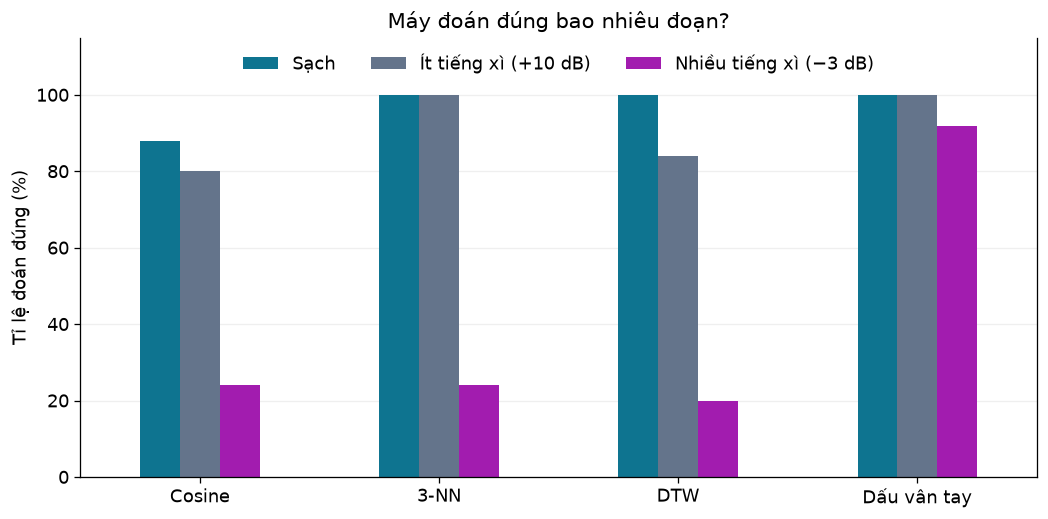

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
(correct / totals * 100).plot.bar(ax=ax, color=["#0e7490", "#64748b", "#a21caf"], rot=0)
ax.set(title="Máy đoán đúng bao nhiêu đoạn?", xlabel="",
       ylabel="Tỉ lệ đoán đúng (%)", ylim=(0, 115), yticks=range(0, 101, 20))
ax.legend(loc="upper center", ncol=3, frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.show()

### Ma trận nhầm lẫn ở mức −3 dB

**Hiểu nhanh.** Đọc hàng để biết bài thật rồi đọc cột để biết máy gọi tên bài
gì. Ô A–A là số lần nhận đúng *Für Elise*. Ô A–B là số lần nghe *Für Elise*
nhưng gọi là *Jingle Bells*.

**Trong ô mã.** Đếm số dự đoán theo từng cặp nhãn thật và nhãn dự đoán. Giữ
cùng thứ tự A–E và thang màu 0–5 cho bốn ma trận. Cộng các ô trên đường chéo
để kiểm tra tổng số dự đoán đúng.

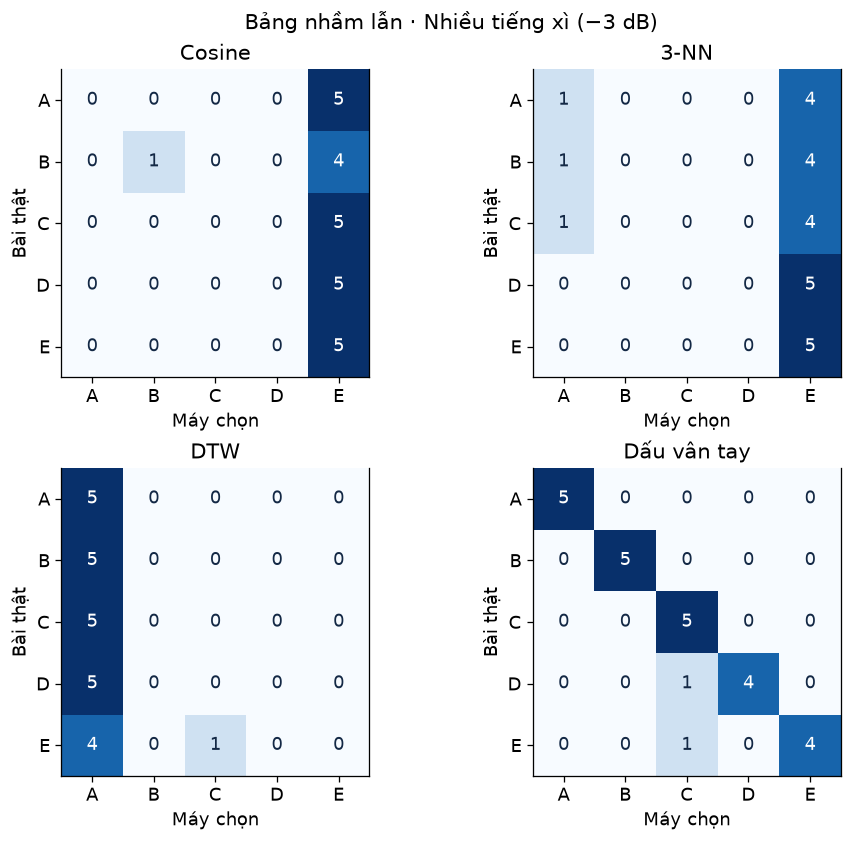

**A** Für Elise · **B** Jingle Bells · **C** Maple Leaf Rag · **D** In the Hall of the Mountain King · **E** Giao hưởng số 5

In [12]:
codes = list(RECORDINGS)
noisy = results[results["Mức nhiễu"] == "Nhiều tiếng xì (−3 dB)"]
fig, axes = plt.subplots(2, 2, figsize=(8.2, 7.2), layout="constrained")
fig.suptitle("Bảng nhầm lẫn · Nhiều tiếng xì (−3 dB)")
for method, ax in zip(methods, axes.flat):
    subset = noisy[noisy["Cách đoán"] == method]
    matrix = pd.crosstab(subset["Bài thật"], subset["Máy chọn"]).reindex(
        index=codes, columns=codes, fill_value=0)
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=5)
    for row in range(len(codes)):
        for column in range(len(codes)):
            count = matrix.iloc[row, column]
            ax.text(column, row, count, ha="center", va="center",
                    color="white" if count >= 3 else "#132845")
    ax.set(title=method, xlabel="Máy chọn", ylabel="Bài thật",
           xticks=range(len(codes)), yticks=range(len(codes)),
           xticklabels=codes, yticklabels=codes)
plt.show()
display(Markdown(" · ".join(f"**{key}** {row[0]}" for key, row in RECORDINGS.items())))

### Kết quả và diễn giải

Trên đoạn sạch, 3-NN, DTW và dấu vân tay cùng đạt **25/25**, còn cosine đạt
**22/25**. Ở −3 dB, dấu vân tay đạt **23/25**, so với **6/25** của cosine
và 3-NN và **5/25** của DTW. Hai lỗi của dấu vân tay nằm ở ô D–C và E–C.
Cột E của cosine cho thấy phương pháp này dồn hầu hết dự đoán về một bản thu.

**Hiểu nhanh.** Tưởng tượng một tấm ảnh có thêm nhiều hạt bụi. Cả bức ảnh có
thể trông khác, nhưng vài điểm sáng vẫn ở đúng chỗ so với nhau. Máy có thể dùng
những điểm đó để lần về ảnh gốc. Dấu vân tay dùng ý tưởng tương tự với âm thanh.

Trong phép thử này, các cặp đỉnh còn khớp tạo ra một cụm phiếu cùng độ lệch.
Đây là một cách giải thích phù hợp với cơ chế của phương pháp. Bảng điểm đo
khả năng nhận diện và chưa đo trực tiếp tỉ lệ đỉnh còn giữ được sau khi thêm nhiễu.

## 7. Giới hạn và hướng kiểm tra tiếp

- Kho có năm bản thu và mỗi điều kiện có 25 đoạn. Tỉ lệ đúng là mô tả của mẫu
  này. Các đoạn chồng lấn hoặc đi ra từ cùng bản thu có thể cho lỗi tương quan.
- Nhiễu Gaussian chỉ mô phỏng tiếng xì. Để đánh giá trong phòng thật, có thể
  thu lại đoạn phát qua loa rồi ghi bằng mic ở các khoảng cách khác nhau.
- Nhận diện giai điệu qua bản phối khác, tiếng hát hoặc huýt sáo cần bộ thử riêng.
  Nhận diện bài ngoài kho cần thêm lựa chọn từ chối và đo số lần báo nhầm.
- Có thể đổi `CLIP_SECONDS` hoặc SNR, chạy lại và đối chiếu bảng mới với
  bảng mặc định. Phần diễn giải phía trên ghi kết quả của cấu hình gốc.

## Tài liệu tham khảo

- `deep-research-report.md`, báo cáo nghiên cứu dùng để chọn đặc trưng,
  phương pháp đối sánh và cách đánh giá.
- Avery Li-Chun Wang (2003), *An Industrial-Strength Audio Search Algorithm*.
  Cách ghép cặp đỉnh và bỏ phiếu theo độ lệch thời gian trong notebook lấy ý tưởng
  từ công trình này. [Bài báo ISMIR](https://labrosa.ee.columbia.edu/~dpwe/papers/Wang03-shazam.pdf)